<a href="https://colab.research.google.com/github/nara-yama/osurankreg/blob/main/selfcomparisontoolosu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
from google.colab import userdata
import requests

client_id = int(userdata.get("OSU_CLIENT_ID"))
client_secret = userdata.get("OSU_CLIENT_SECRET")

token_res = requests.post("https://osu.ppy.sh/oauth/token", data={
    "client_id": client_id,
    "client_secret": client_secret,
    "grant_type": "client_credentials",
    "scope": "public"
})
token = token_res.json()["access_token"]
H = {"Authorization": f"Bearer {token}"}

In [ ]:
def progress(done, total, width=30):
    filled = int(width * done / total)
    bar = "█" * filled + "-" * (width - filled)
    print(f"\r[{bar}] {done}/{total} pages ({done/total:.0%}) | {len(rows)} players", end="", flush=True)

def process(START, END):
  for i, page in enumerate(range(START, END + 1), start=1):
    url = "https://osu.ppy.sh/api/v2/rankings/osu/performance"
    params = {"country": "ID", "cursor[page]": page}
    r = requests.get(url, headers=H, params=params)
    if r.status_code == 429:
        time.sleep(10)
        r = requests.get(url, headers=H, params=params)
    r.raise_for_status()
    for s in r.json()["ranking"]:
        rows.append({
            "user_id": s["user"]["id"],
            "username": s["user"]["username"],
            "global_rank": s.get("global_rank"),
            "pp": s["pp"],
            "hours": s["play_time"] / 3600,
        })
    progress(i, total)
    time.sleep(1.1)
  print("\nDone!")
  return pd.DataFrame(rows)

#Global ("all" digit dataset)
ID leaderboard page 1 - 200

In [3]:
import requests, time
import pandas as pd
import matplotlib.pyplot as plt

START, END = 1, 200
total = END - START + 1
rows = []

progress(0, total)
df = process(START, END)


[██████████████████████████████] 200/200 pages (100%) | 10000 players
Done!


In [ ]:
#optional add top 50 pages global (for higher rank accuracies)
rows_g = []
for page in range(1, 50):
    url = "https://osu.ppy.sh/api/v2/rankings/osu/performance"
    params = {"cursor[page]": page}          # no country filter
    r = requests.get(url, headers=H, params=params)
    if r.status_code == 429:
        time.sleep(10)
        r = requests.get(url, headers=H, params=params)
    r.raise_for_status()
    for s in r.json()["ranking"]:
        rows_g.append({
            "user_id": s["user"]["id"],
            "username": s["user"]["username"],
            "global_rank": s.get("global_rank"),
            "pp": s["pp"],
            "hours": s["play_time"] / 3600,
        })
    print(f"\r{page}/10", end="", flush=True)
    time.sleep(1.1)

df_g = pd.DataFrame(rows_g).dropna(subset=["global_rank"])
df_all = pd.concat([df, df_g]).drop_duplicates("user_id").reset_index(drop=True)
print(f"\n{len(df)} -> {len(df_all)} players")
df = df_all[df_all.hours > 0].sort_values("global_rank").reset_index(drop=True)

10/10
10000 -> 10495 players


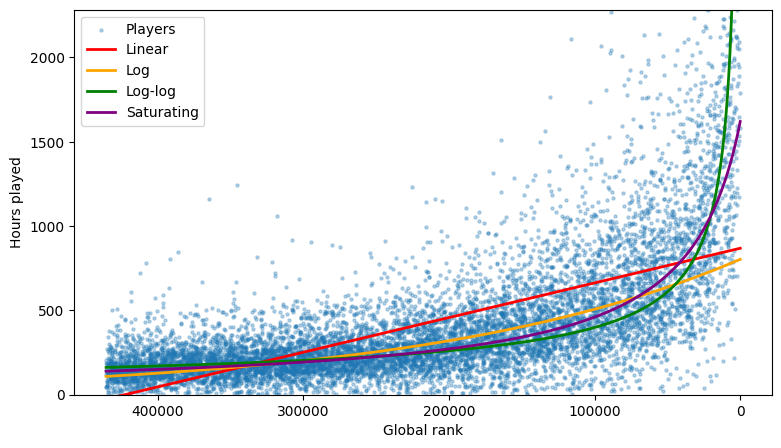

In [8]:
from scipy.optimize import curve_fit
from scipy import stats
import numpy as np

df = df[df.hours > 0]
x = df.global_rank.values
y = df.hours.values

lin = stats.linregress(x, y)
log = stats.linregress(x, np.log(y))
pl  = stats.linregress(np.log(x), np.log(y))

def sat_log(lr, logH, logr0, k):
    return logH - np.log1p(np.exp(k * (lr - logr0)))
p0 = [np.log(3000), np.log(5000), 0.5]
popt, _ = curve_fit(sat_log, np.log(x), np.log(y), p0=p0, maxfev=20000)
H, r0, k = np.exp(popt[0]), np.exp(popt[1]), popt[2]
def pred_lin(r): return lin.intercept + lin.slope * r
def pred_log(r): return np.exp(log.intercept + log.slope * r)
def pred_pl(r):  return np.exp(pl.intercept + pl.slope * np.log(r))
def pred_sat(r): return np.exp(sat_log(np.log(r), *popt))   # NEW

xs = np.linspace(x.min(), x.max(), 500)
plt.figure(figsize=(9, 5))
plt.scatter(x, y, s=5, alpha=0.3, label="Players")
plt.plot(xs, pred_lin(xs), color="red", lw=2, label="Linear")
plt.plot(xs, pred_log(xs), color="orange", lw=2, label="Log")
plt.plot(xs, pred_pl(xs), color="green", lw=2, label="Log-log")
plt.plot(xs, pred_sat(xs), color="purple", lw=2, label="Saturating")   # NEW
plt.xlabel("Global rank"); plt.ylabel("Hours played")
plt.ylim(0, np.percentile(y, 99) * 1.1)   # stops outliers squashing the plot
plt.legend()
plt.gca().invert_xaxis()
plt.show()

In [10]:
s = input("Input rank (blank to stop): ").strip()

r = int(s.replace(",", ""))
print(f"  Rank {r:,} → lin: {max(pred_lin(r), 0):.0f} | log: {pred_log(r):.0f} | log-log: {pred_pl(r):.0f} | saturating: {pred_sat(r):.0f} h")

Input rank (blank to stop): 109500
  Rank 109,500 → lin: 644 | log: 485 | log-log: 377 | saturating: 432 h


#For 5 digits

In [16]:
import requests, time
import pandas as pd
import matplotlib.pyplot as plt

START, END = 5, 45
total = END - START + 1
rows = []
progress(0, total)
df = process(START, END)

[██████████████████████████████] 41/41 pages (100%) | 2050 players
Done!


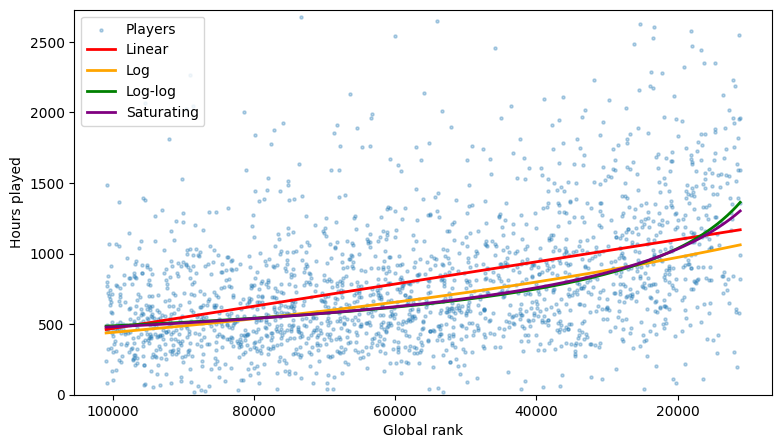

In [18]:
from scipy.optimize import curve_fit
from scipy import stats
import numpy as np
df = pd.DataFrame(rows)
df = df[df.hours > 0]
x = df.global_rank.values
y = df.hours.values
# print(len(df), x.min(), x.max())

lin = stats.linregress(x, y)
log = stats.linregress(x, np.log(y))
pl  = stats.linregress(np.log(x), np.log(y))

p0 = [np.log(3000), np.log(5000), 0.5]
popt, _ = curve_fit(sat_log, np.log(x), np.log(y), p0=p0, maxfev=20000)
H, r0, k = np.exp(popt[0]), np.exp(popt[1]), popt[2]

xs = np.linspace(x.min(), x.max(), 500)
plt.figure(figsize=(9, 5))
plt.scatter(x, y, s=5, alpha=0.3, label="Players")
plt.plot(xs, pred_lin(xs), color="red", lw=2, label="Linear")
plt.plot(xs, pred_log(xs), color="orange", lw=2, label="Log")
plt.plot(xs, pred_pl(xs), color="green", lw=2, label="Log-log")
plt.plot(xs, pred_sat(xs), color="purple", lw=2, label="Saturating")   # NEW
plt.xlabel("Global rank"); plt.ylabel("Hours played")
plt.ylim(0, np.percentile(y, 99) * 1.1)   # stops outliers squashing the plot
plt.legend()
plt.gca().invert_xaxis()
plt.show()

In [19]:
s = input("Input rank (blank to stop): ").strip()

r = int(s.replace(",", ""))
print(f"  Rank {r:,} → lin: {max(pred_lin(r), 0):.0f} | log: {pred_log(r):.0f} | log-log: {pred_pl(r):.0f} | saturating: {pred_sat(r):.0f} h")

Input rank (blank to stop): 92500
  Rank 92,500 → lin: 529 | log: 476 | log-log: 506 | saturating: 501 h


#For 6 digits

In [ ]:
import requests, time
import pandas as pd
import matplotlib.pyplot as plt

START, END = 45, 200
total = END - START + 1
rows = []
progress(0, total)
df = process(START, END)

[██████████████████████████████] 156/156 pages (100%) | 7800 players
Done!


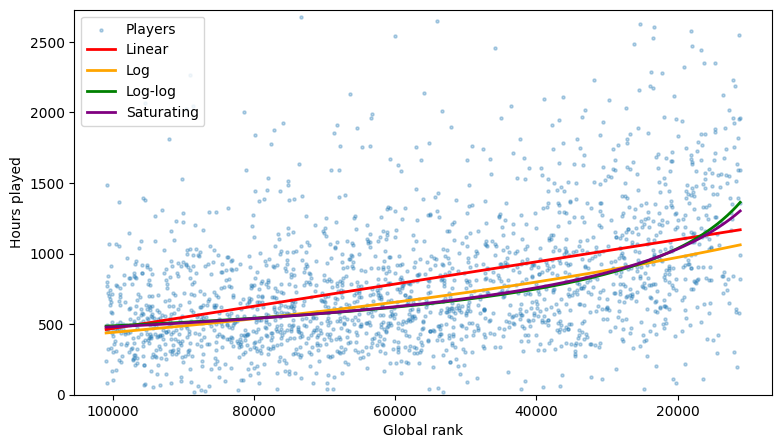

In [20]:
from scipy.optimize import curve_fit
from scipy import stats
import numpy as np
df = pd.DataFrame(rows)
df = df[df.hours > 0]
x = df.global_rank.values
y = df.hours.values
# print(len(df), x.min(), x.max())

lin = stats.linregress(x, y)
log = stats.linregress(x, np.log(y))
pl  = stats.linregress(np.log(x), np.log(y))

p0 = [np.log(3000), np.log(5000), 0.5]
popt, _ = curve_fit(sat_log, np.log(x), np.log(y), p0=p0, maxfev=20000)
H, r0, k = np.exp(popt[0]), np.exp(popt[1]), popt[2]

xs = np.linspace(x.min(), x.max(), 500)
plt.figure(figsize=(9, 5))
plt.scatter(x, y, s=5, alpha=0.3, label="Players")
plt.plot(xs, pred_lin(xs), color="red", lw=2, label="Linear")
plt.plot(xs, pred_log(xs), color="orange", lw=2, label="Log")
plt.plot(xs, pred_pl(xs), color="green", lw=2, label="Log-log")
plt.plot(xs, pred_sat(xs), color="purple", lw=2, label="Saturating")   # NEW
plt.xlabel("Global rank"); plt.ylabel("Hours played")
plt.ylim(0, np.percentile(y, 99) * 1.1)   # stops outliers squashing the plot
plt.legend()
plt.gca().invert_xaxis()
plt.show()

In [21]:
s = input("Input rank (blank to stop): ").strip()

r = int(s.replace(",", ""))
print(f"  Rank {r:,} → lin: {max(pred_lin(r), 0):.0f} | log: {pred_log(r):.0f} | log-log: {pred_pl(r):.0f} | saturating: {pred_sat(r):.0f} h")

Input rank (blank to stop): 92500
  Rank 92,500 → lin: 529 | log: 476 | log-log: 506 | saturating: 501 h


#Evaluation tool

In [ ]:
from sklearn.model_selection import KFold
from scipy import stats
from scipy.optimize import curve_fit
from scipy.interpolate import LSQUnivariateSpline

d = df[df.hours > 0].sort_values("global_rank").reset_index(drop=True)
X = d.global_rank.values.astype(float)
Y = d.hours.values.astype(float)

# ---- each fit_* takes (x, y) and returns a predict(rank) function ----
def fit_lin(x, y):
    m = stats.linregress(x, y)
    return lambda r: np.maximum(m.intercept + m.slope * np.asarray(r, float), 1)

def fit_log(x, y):
    m = stats.linregress(x, np.log(y))
    return lambda r: np.exp(m.intercept + m.slope * np.asarray(r, float))

def fit_pl(x, y):
    m = stats.linregress(np.log(x), np.log(y))
    return lambda r: np.exp(m.intercept + m.slope * np.log(np.asarray(r, float)))

def _sat(lr, logH, logr0, k):
    return logH - np.log1p(np.exp(k * (lr - logr0)))

def fit_sat(x, y):
    p, _ = curve_fit(_sat, np.log(x), np.log(y),
                     p0=[np.log(3000), np.log(5000), 0.5], maxfev=20000)
    return lambda r: np.exp(_sat(np.log(np.asarray(r, float)), *p))

def fit_spl(x, y):
    o = np.argsort(x); x, y = x[o], y[o]
    lx, ly = np.log10(x), np.log10(y)
    kr = np.array([10, 50, 200, 1000, 5000, 20000, 80000, 250000])
    kn = np.log10(kr[(kr > x.min()) & (kr < x.max())])
    s = LSQUnivariateSpline(lx, ly, t=kn, k=3)
    lo, hi = lx.min(), lx.max()
    sl_lo, sl_hi = s.derivative()(lo), s.derivative()(hi)
    def pred(r):
        l = np.log10(np.asarray(r, float))
        out = s(np.clip(l, lo, hi))
        out = out + np.where(l > hi, sl_hi * (l - hi), 0) + np.where(l < lo, sl_lo * (l - lo), 0)
        return 10 ** out
    return pred

models = {"Linear": fit_lin, "Log": fit_log, "Log-log": fit_pl,
          "Saturating": fit_sat, "Log-log spline": fit_spl}

# ---- 5-fold cross-validation: out-of-sample predictions for every player ----
oof = {name: np.full(len(X), np.nan) for name in models}
for tr, te in KFold(5, shuffle=True, random_state=0).split(X):
    for name, fit in models.items():
        try:
            oof[name][te] = fit(X[tr], Y[tr])(X[te])
        except Exception as e:
            print(f"{name} failed on a fold: {e}")

# ---- metrics ----
def metrics(y, p):
    ok = ~np.isnan(p)
    y, p = y[ok], p[ok]
    return {
        "R²": 1 - np.sum((y - p)**2) / np.sum((y - y.mean())**2),
        "RMSE (h)": np.sqrt(np.mean((y - p)**2)),
        "MAE (h)": np.mean(np.abs(y - p)),
        "Median |err| %": 100 * np.median(np.abs(y - p) / y),
        "Bias % (median)": 100 * (np.median(p / y) - 1),   # negative = underselling
    }

overall = pd.DataFrame({n: metrics(Y, p) for n, p in oof.items()}).T
print("=== Overall (held-out) ===")
print(overall.round(2).to_string())

# ---- by rank range ----
edges = [0, 100, 1_000, 10_000, 100_000, 1e7]
labels = ["1-100", "101-1k", "1k-10k", "10k-100k", "100k+"]
bucket = pd.cut(X, edges, labels=labels)

=== Overall (held-out) ===
                  R²  RMSE (h)  MAE (h)  Median |err| %  Bias % (median)
Linear          0.40    471.73   292.58           62.81            16.48
Log             0.40    471.11   232.30           34.98            -5.18
Log-log        -0.50    745.88   273.16           36.64            -5.55
Saturating      0.68    344.78   192.09           31.57            -6.65
Log-log spline  0.68    342.95   191.54           31.58            -6.82
